# Image Segmentation using CLIPSeg

Este notebook utiliza o modelo `CIDAS/clipseg-rd64-refined` da Hugging Face para realizar a segmentação de imagens (zero-shot image segmentation) localizadas na pasta `imagens/` a partir de categorias (prompts) textuais.

In [2]:
import os
import torch
import matplotlib.pyplot as plt
from PIL import Image
from transformers import CLIPSegProcessor, CLIPSegForImageSegmentation

# Carregar o modelo e o processador da Hugging Face
model_id = "CIDAS/clipseg-rd64-refined"
processor = CLIPSegProcessor.from_pretrained(model_id)
model = CLIPSegForImageSegmentation.from_pretrained(model_id)

Loading weights: 100%|██████████| 462/462 [00:00<00:00, 7001.54it/s]
CLIPSegForImageSegmentation LOAD REPORT from: CIDAS/clipseg-rd64-refined
Key                                       | Status     |  | 
------------------------------------------+------------+--+-
clip.vision_model.embeddings.position_ids | UNEXPECTED |  | 
clip.text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## Função de Segmentação

Abaixo definimos uma função auxiliar capaz de receber o caminho de uma imagem e uma lista de textos (prompts) que desejamos buscar/segmentar.

In [4]:
def segment_image(image_path, prompts):
    # Carregar a imagem da pasta imagens
    image = Image.open(image_path).convert("RGB")
    
    # Preparar as entradas. Uma vez que analisaremos vários prompts para uma mesma imagem, repetimos a imagem.
    inputs = processor(
        text=prompts,
        images=[image] * len(prompts),
        padding="max_length",
        return_tensors="pt"
    )
    
    # Realizar a inferência
    with torch.no_grad():
        outputs = model(**inputs)
    
    # Obter os logits resultantes
    preds = outputs.logits
    
    # Ajustar a dimensão caso seja passado apenas 1 prompt
    if len(prompts) == 1:
        preds = preds.unsqueeze(0)
        
    # Plotar o resultado
    _, ax = plt.subplots(1, len(prompts) + 1, figsize=(4 * (len(prompts) + 1), 4))
    ax[0].imshow(image)
    ax[0].axis("off")
    ax[0].set_title("Imagem Original")
    
    for i, prompt in enumerate(prompts):
        # Converter de logits para probabilidades (0 a 1) usando sigmoid
        mask = torch.sigmoid(preds[i])
        
        # Exibir as máscaras na cor map 'viridis' 
        ax[i+1].imshow(mask, vmin=0, vmax=1)
        ax[i+1].axis("off")
        ax[i+1].set_title(prompt)
        
    plt.tight_layout()
    plt.show()

## Testes com imagens locais

Vamos aplicar a segmentação zero-shot nas diferentes imagens da pasta `imagens/`.

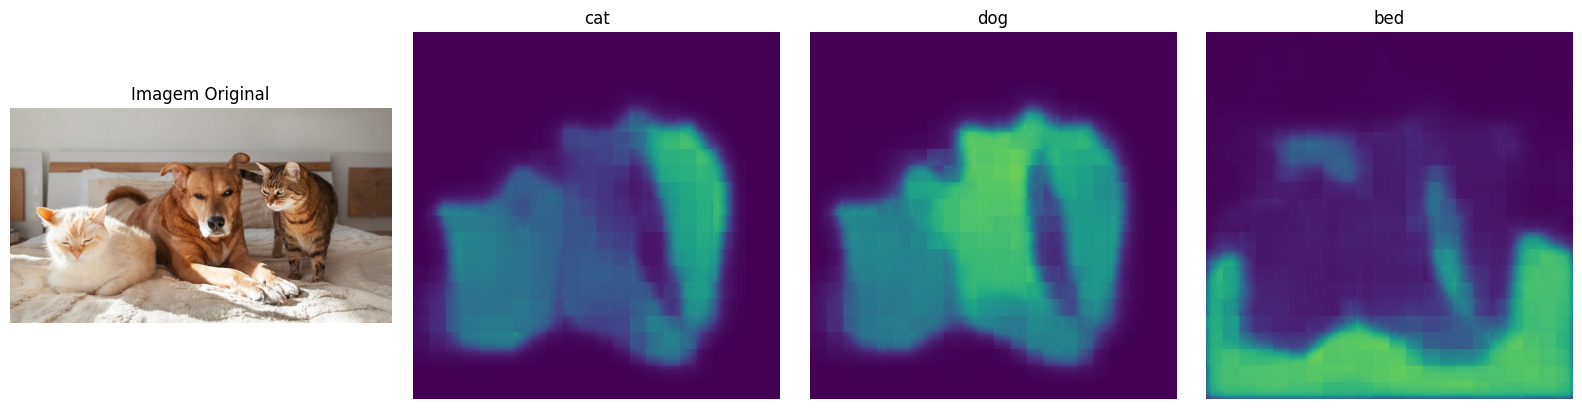

In [8]:
# Exemplo 1: cães e gatos
img_path_1 = "imagens/cats_dog.png"
prompts_1 = ["cat", "dog", "bed"]
segment_image(img_path_1, prompts_1)

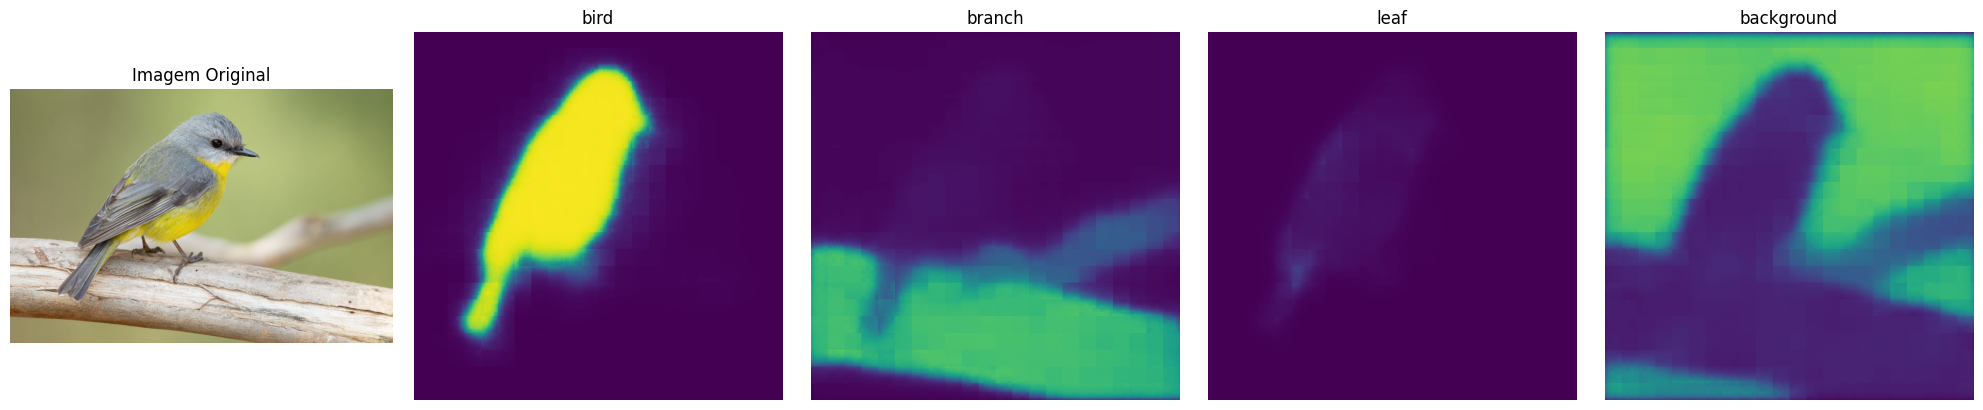

In [9]:
# Exemplo 2: pássaro
img_path_2 = "imagens/bird.jpg"
prompts_2 = ["bird", "branch", "leaf", "background"]
segment_image(img_path_2, prompts_2)

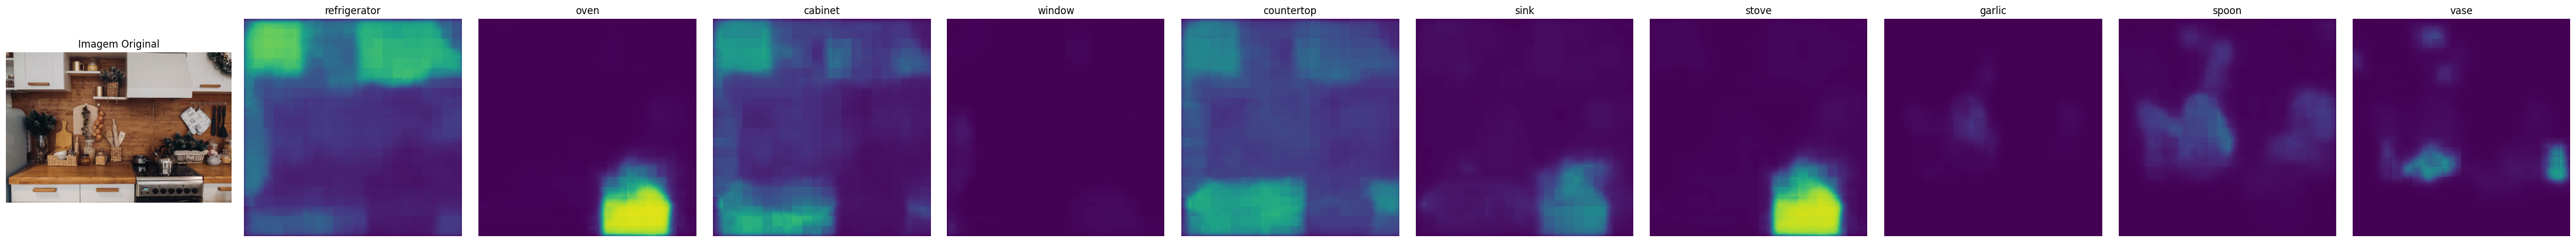

In [10]:
# Exemplo 3: janela e cozinha
img_path_3 = "imagens/kitchen.png"
prompts_3 = ["refrigerator", "oven", "cabinet", "window", "countertop", "sink", "stove", "garlic", "spoon", "vase"]
segment_image(img_path_3, prompts_3)

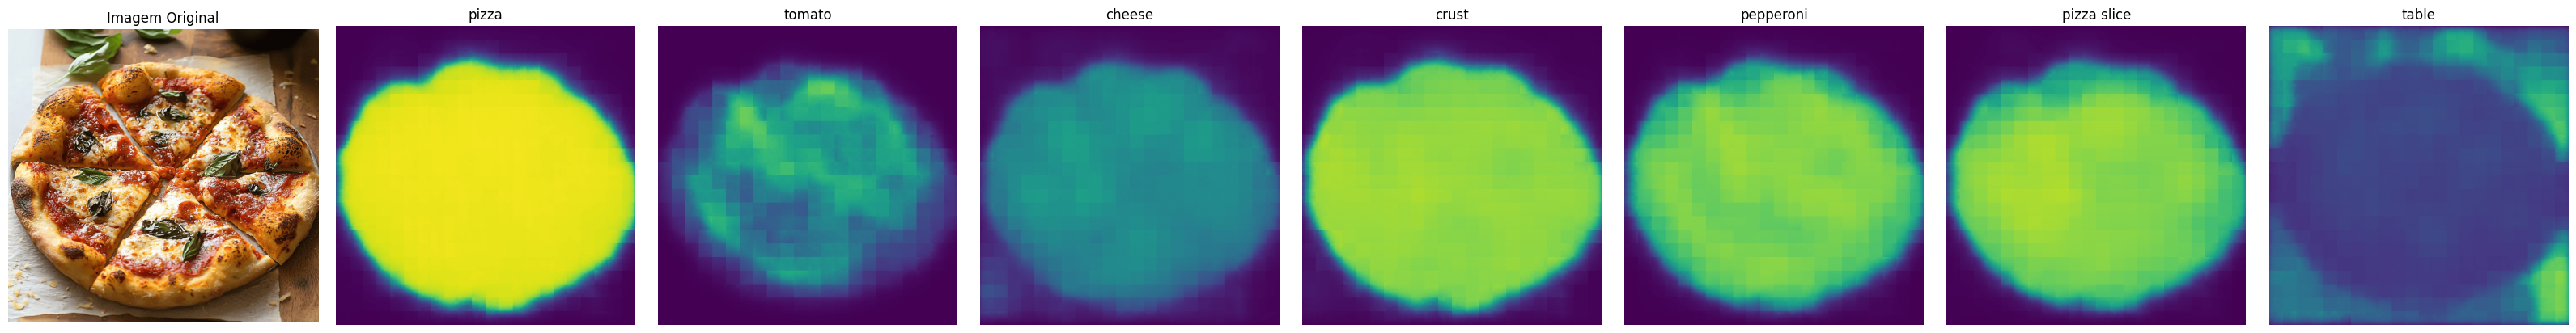

In [11]:
# Exemplo 4: pizza
img_path_4 = "imagens/pizza.png"
prompts_4 = ["pizza", "tomato", "cheese", "crust", "pepperoni", "pizza slice", "table"]
segment_image(img_path_4, prompts_4)